# Avaliação ampliada: todos os subitens, todas as praças

**Ponto de parada da fase de aplicação.** Antes de prever e publicar para o site, a Squad confere se o método escolhido funciona fora do recorte da primeira avaliação (45 subitens, só Brasil): agora são **todos os subitens do IPCA nas 17 localidades** (16 praças e o Brasil).

**Candidatos:** ingênua, ingênua sazonal, regressões linear e logarítmica pela tendência e um **XGBoost único** para todas as praças, com a praça como variável. O clima e as regressões pelo nível ficaram de fora pela primeira avaliação.

**Escolha por subitem:** para cada subitem, juntando as praças, vence o candidato de menor erro; onde o vencedor não consegue prever, usa-se a ingênua. Para medir a escolha sem trapaça, ela é feita com os primeiros 24 meses de teste e medida nos 12 seguintes, que ela não viu.

Walk-forward de 36 meses, como antes. Para refazer: `just modelo-notebook`.

In [1]:
import time
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

from inflatrack.predicao.escolha import avaliar_escolha, escolher_por_subitem
from inflatrack.predicao.serie import carregar_gold
from inflatrack.predicao.walk_forward import avaliar, metricas, origens_de_teste

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DUCKDB = RAIZ / "data/duckdb/inflatrack.duckdb"
CANDIDATOS = (
    "ingenua",
    "ingenua_sazonal",
    "linear_tendencia",
    "logaritmica_tendencia",
    "xgboost_sem_clima",
)
MESES_TESTE = 36
MESES_ESCOLHA = 24

NOMES_MODELO = {
    "ingenua": "Ingênua",
    "ingenua_sazonal": "Ingênua sazonal",
    "linear_tendencia": "Linear (tendência)",
    "logaritmica_tendencia": "Logarítmica (tendência)",
    "xgboost_sem_clima": "XGBoost",
    "escolha_por_subitem": "Escolha por subitem",
}
NOMES_GRUPO = {
    "1": "Alimentação e bebidas",
    "2": "Habitação",
    "3": "Artigos de residência",
    "4": "Vestuário",
    "5": "Transportes",
    "6": "Saúde e cuidados pessoais",
    "7": "Despesas pessoais",
    "8": "Educação",
    "9": "Comunicação",
}
with duckdb.connect(str(DUCKDB), read_only=True) as conexao:
    pracas = conexao.sql("select codigo_localidade, nome_localidade from gold.dim_localidade").df()
NOME_PRACA = dict(zip(pracas.codigo_localidade, pracas.nome_localidade, strict=True))
pd.set_option("display.precision", 3)

## Dados

In [2]:
base = carregar_gold(DUCKDB, codigos=None, codigo_localidade=None)
series = base[["codigo_localidade", "codigo_subitem"]].drop_duplicates()
print(
    f"{len(base):,} linhas, {len(series):,} séries (praça x subitem), "
    f"{base.codigo_subitem.nunique()} subitens, {base.codigo_localidade.nunique()} praças"
)

984,620 linhas, 6,509 séries (praça x subitem), 478 subitens, 17 praças


In [3]:
inicio = time.perf_counter()
origens = origens_de_teste(base, MESES_TESTE)
previsoes = avaliar(base, origens, modelos=CANDIDATOS)
previsoes["grupo_ipca"] = previsoes.codigo_subitem.str[0].map(NOMES_GRUPO)
previsoes["praca"] = previsoes.codigo_localidade.map(NOME_PRACA)
minutos = (time.perf_counter() - inicio) / 60
primeiro, ultimo = (o + pd.DateOffset(months=1) for o in (origens[0], origens[-1]))
print(f"{len(previsoes):,} previsões de {primeiro:%m/%Y} a {ultimo:%m/%Y} em {minutos:.1f} min")

728,100 previsões de 11/2023 a 10/2026 em 7.7 min


## Resultado geral dos candidatos (36 meses)

MAE em pontos percentuais da variação mensal; `ganho_sobre_ingenua` = `1 − MAE / MAE da ingênua`. Todos medidos nas mesmas linhas.

In [4]:
geral = metricas(previsoes).assign(modelo=lambda d: d.modelo.map(NOMES_MODELO))
geral.sort_values("mae").set_index("modelo")

,mae,rmse,n,ganho_sobre_ingenua
modelo,,,,
XGBoost,1.699,3.384,145620,0.289
Logarítmica (tendência),1.776,3.708,145620,0.257
Linear (tendência),1.836,3.791,145620,0.232
Ingênua sazonal,2.314,4.645,145620,0.031
Ingênua,2.389,4.816,145620,0.000


## Por grupo do IPCA (MAE)

In [5]:
por_grupo = metricas(previsoes, por=["grupo_ipca"])
por_grupo["modelo"] = por_grupo.modelo.map(NOMES_MODELO)
por_grupo.pivot(index="grupo_ipca", columns="modelo", values="mae")

modelo,Ingênua,Ingênua sazonal,Linear (tendência),Logarítmica (tendência),XGBoost
grupo_ipca,,,,,
Alimentação e bebidas,3.494,3.579,2.816,2.726,2.503
Artigos de residência,1.909,1.838,1.418,1.396,1.396
Comunicação,0.685,0.698,0.638,0.519,0.634
Despesas pessoais,1.743,1.562,1.269,1.232,1.225
Educação,1.171,0.676,0.940,0.774,0.873
Habitação,1.620,1.508,1.137,1.116,1.130
Saúde e cuidados pessoais,1.666,1.510,1.132,1.129,1.114
Transportes,2.657,2.488,1.912,1.840,1.846
Vestuário,1.806,1.656,1.331,1.320,1.277


## Por praça: ganho do XGBoost sobre a ingênua

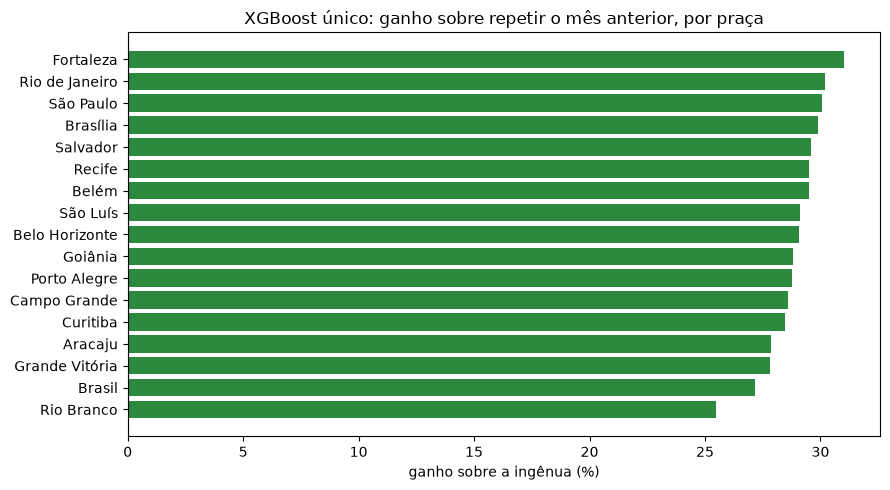

In [6]:
por_praca = metricas(previsoes, por=["praca"])
xgb_praca = (
    por_praca[por_praca.modelo == "xgboost_sem_clima"]
    .set_index("praca")
    .sort_values("ganho_sobre_ingenua")
)
fig, eixo = plt.subplots(figsize=(9, 5))
cores = ["#c92a2a" if g < 0 else "#2b8a3e" for g in xgb_praca.ganho_sobre_ingenua]
eixo.barh(xgb_praca.index, 100 * xgb_praca.ganho_sobre_ingenua, color=cores)
eixo.axvline(0, color="black", lw=0.8)
eixo.set_xlabel("ganho sobre a ingênua (%)")
eixo.set_title("XGBoost único: ganho sobre repetir o mês anterior, por praça")
plt.tight_layout()

In [7]:
xgb_praca[["mae", "rmse", "n", "ganho_sobre_ingenua"]]

,mae,rmse,n,ganho_sobre_ingenua
praca,,,,
Rio Branco,1.633,3.070,8028,0.255
Brasil,1.444,3.012,13572,0.272
Grande Vitória,1.716,3.419,7848,0.278
Aracaju,1.611,2.876,7848,0.279
Curitiba,1.824,3.488,8640,0.285
Campo Grande,1.736,3.309,8280,0.286
Porto Alegre,1.817,5.173,8568,0.288
Goiânia,1.635,3.194,8136,0.288
Belo Horizonte,1.738,3.614,8316,0.291


## Quem vence por subitem

Contagem dos subitens em que cada candidato teve o menor erro nos 36 meses (juntando as praças). É só descritivo: a medida honesta da escolha vem a seguir.

In [8]:
vencedores = escolher_por_subitem(previsoes)
vencedores.modelo.map(NOMES_MODELO).value_counts().rename("subitens").to_frame()

,subitens
modelo,
XGBoost,210
Logarítmica (tendência),132
Ingênua sazonal,15
Linear (tendência),12
Ingênua,8


## A escolha por subitem, medida nos meses que ela não viu

Escolha com os primeiros 24 meses de teste; medida nos últimos 12, contra os candidatos nos mesmos meses.

In [9]:
fora = avaliar_escolha(previsoes, meses_escolha=MESES_ESCOLHA)
honesta = metricas(fora).assign(modelo=lambda d: d.modelo.map(NOMES_MODELO))
honesta.sort_values("mae").set_index("modelo")

,mae,rmse,n,ganho_sobre_ingenua
modelo,,,,
Escolha por subitem,1.643,3.349,48540,0.307
XGBoost,1.660,3.331,48540,0.299
Logarítmica (tendência),1.743,3.651,48540,0.265
Linear (tendência),1.799,3.776,48540,0.241
Ingênua sazonal,2.257,4.438,48540,0.048
Ingênua,2.370,4.759,48540,0.000


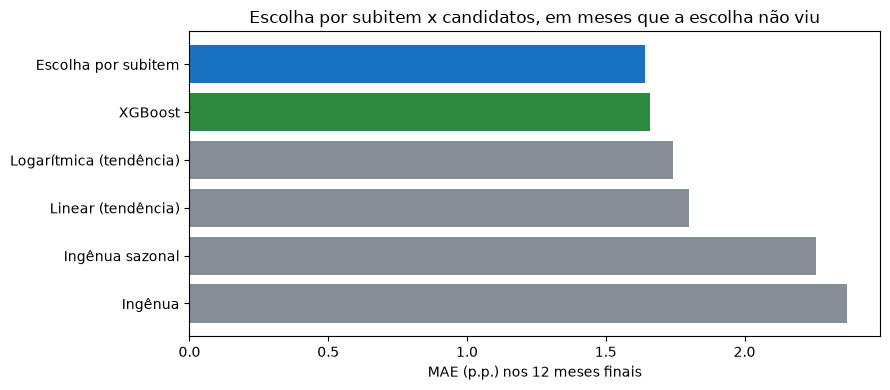

In [10]:
ordem = honesta.sort_values("mae")
fig, eixo = plt.subplots(figsize=(9, 4))
cores = [
    "#1971c2" if m == "Escolha por subitem" else "#2b8a3e" if m == "XGBoost" else "#868e96"
    for m in ordem.modelo
]
eixo.barh(ordem.modelo, ordem.mae, color=cores)
eixo.invert_yaxis()
eixo.set_xlabel("MAE (p.p.) nos 12 meses finais")
eixo.set_title("Escolha por subitem x candidatos, em meses que a escolha não viu")
plt.tight_layout()

In [11]:
uso = fora[fora.modelo == "escolha_por_subitem"].modelo_usado.map(NOMES_MODELO)
uso.value_counts(normalize=True).rename("parcela das previsões").to_frame()

,parcela das previsões
modelo_usado,
XGBoost,0.504
Logarítmica (tendência),0.379
Linear (tendência),0.047
Ingênua sazonal,0.036
Ingênua,0.034


## Conclusão

Números da execução de 19/11/2026: 478 subitens em 17 localidades (6.509 séries) e 36 meses previstos (nov/2023 a out/2026), num total de 145.620 previsões comparáveis por candidato.

1. **O XGBoost único para todas as praças funciona.** Ele erra em média **1,70 p.p.**, contra 2,39 p.p. da ingênua, um ganho de **29%**. O ganho aparece em **todas as 17 localidades**, entre 25% (Rio Branco) e 31% (Fortaleza), então treinar um modelo só para todas as praças não prejudica nenhuma delas.
2. **Com todos os subitens, as regressões pela tendência melhoram muito.** A logarítmica fica em 1,78 p.p. (+26%) e a linear em 1,84 p.p. (+23%). Na primeira avaliação (45 subitens, só Brasil), elas empatavam com a ingênua. Os subitens de serviços e de preço administrado, que variam pouco e de forma regular, favorecem a tendência.
3. **Quem vence por subitem:** o XGBoost em 210 subitens, a regressão logarítmica em 132, a ingênua sazonal em 15, a regressão linear em 12 e a ingênua em 8.
4. **A escolha por subitem, medida nos 12 meses que ela não viu**, erra 1,64 p.p., contra 1,66 p.p. do XGBoost sozinho e 2,37 p.p. da ingênua.
   - Ela ganha da ingênua com folga (31%), o que cumpre a regra de segurança do design.
   - Sobre o XGBoost sozinho, o ganho é pequeno: cerca de 1% no MAE. No RMSE ela fica ligeiramente pior (3,35 contra 3,33), ou seja, erra um pouco mais nos meses de variação grande.
   - Nessas previsões, a escolha usou o XGBoost em 50% dos casos e a logarítmica em 38%.
5. **Onde o XGBoost não é o melhor grupo a grupo:** em comunicação, educação e habitação, a regressão logarítmica ou a ingênua sazonal (educação, por causa do reajuste anual das mensalidades) erram menos. É isso que a escolha por subitem aproveita.

**Decisão para o integrante (ponto de parada):** as duas opções são seguras para publicar.
- A **escolha por subitem** é ligeiramente melhor no MAE, mas mais complexa.
- O **XGBoost fixo** é mais simples e quase igual.
